# Chess upsets over the board
### How large must the rating gap be before an underdog's result is an upset, and does it depend on the time control?

DA2402 · Data Curation and Visualization · IIT Madras · course project report. Team: consult kid + hack coord + high iq (Pradish Gandhi S, Mahir Ali T, Siddharth Maira)

This is the report notebook. It summarises the work of the three analysis notebooks and presents the results:

| Notebook | Content |
|---|---|
| `01_collection.ipynb` | downloads, robots.txt and terms, manifest, parsing, shape / dtypes / meaning of every raw column |
| `02_cleaning.ipynb` | cleaning rules with before/after counts, duplicates, missing values, outliers, cleaning log, storage, data dictionary |
| `03_model.ipynb` | the upset model, critical gaps with intervals, held-out calibration, robustness runs |
| `04_report.ipynb` (this one) | introduction, data and methods, results (figures and tables), conclusion, limitations, attributions |

**Contents.** Abstract · 1 Introduction · 2 Data and methods · 3 Results · 4 Conclusion · 5 Limitations · 6 Attributions · 7 Contributions

**How to run.** From `submission/notebooks/`, *Kernel > Restart & Run All* (a few seconds). The notebook reads only the small tables in `viz/viz_data/` and `reports/` (written by notebooks 02 and 03 and by `viz/make_viz_data.py`); it does not need the large data folder. The figures are drawn by the module `viz/viz.py`, which computes every number in the titles and captions from those tables. Static colour and greyscale copies of every figure are in `viz/renders/`.

In [1]:
import os, re, sys, glob, platform
from importlib import metadata
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import display, Markdown, Image

BASE = ".." if os.path.isdir(os.path.join("..", "viz")) else "."          # works from notebooks/ or from submission/
REPORTS = os.environ.get("CHESS_REPORTS", os.path.join(BASE, "reports"))
sys.path.insert(0, os.path.join(BASE, "viz"))
import viz

pio.renderers.default = "plotly_mimetype+notebook_connected"
T = viz.load2()                       # viz/viz_data/ + reports/model_outputs/
CAP = viz.short_captions(T)           # two to three sentences per figure / table, numbers computed from T

LOG = pd.read_csv(os.path.join(REPORTS, "cleaning_log.csv"))
LOG.columns = ["step_no", "phase", "step", "action", "rows_affected", "rows_left"]
MISS = pd.read_csv(os.path.join(REPORTS, "missingness_tests.csv"))
FIGS = ["fig_games_per_year", "fig_gap_distribution", "fig_outcomes_by_gap", "fig_simpson", "fig_heatmap", "fig_set_compare",
        "fig_upset_points", "fig_model_vs_data", "fig_verified_split", "fig_critical_gap_alpha", "fig_upset_rule",
        "fig_calibration_check", "fig_model_misfit"]
TABS = {"table_critical_gaps": "Critical gap (Elo points) at alpha = 0.10 with 95 % interval and data support",
        "table_differences": "Differences of the critical gap between time controls at alpha = 0.10 (Elo points)",
        "table_robustness": "Critical gaps (band 2200-2499, alpha = 0.10) under five analysis choices (Elo points)"}
LABEL = {f: f"Figure {i}" for i, f in enumerate(FIGS, 1)}
LABEL.update({t: f"Table {i}" for i, t in enumerate(TABS, 5)})


def md(text):
    display(Markdown(text))


def caption(name):
    text = CAP[name]
    for key, lab in LABEL.items():
        text = text.replace(key, lab)
    return text


def show(name, width=1100):
    fig, _ = getattr(viz, name)(T)
    if width:
        fig.update_layout(width=width)
    fig.show()
    md(f"**{LABEL[name]}.** {caption(name)}")


def show_table(name):
    _, table_md = getattr(viz, name)(T)[:2]
    md(f"**{LABEL[name]}. {TABS[name]}**\n\n{table_md}\n\n{caption(name)}")


def fmt(x, d=0):
    return f"{x:,.{d}f}"


def table(df):
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "|".join("---" for _ in df.columns) + "|"
    body = ["| " + " | ".join("" if pd.isna(v) else str(v) for v in r) + " |" for r in df.itertuples(index=False)]
    return "\n".join([head] + body)


# headline numbers used in the text (all read from the tables)
cg = T["critical_gap_empirical"]
def crit(colour, tc, band="2200-2499", alpha=0.10, ci=False):
    r = cg[(cg.underdog_color == colour) & (cg.tc_class == tc) & (cg.band == band) & np.isclose(cg.alpha, alpha)].iloc[0]
    return f"{r.critical_gap:.0f} ({r.lo95:.0f}-{r.hi95:.0f})" if ci else f"{r.critical_gap:.0f}"

dif = T["critical_gap_diff_empirical"]
def diffv(colour, pair, band="2200-2499", alpha=0.10):
    r = dif[(dif.underdog_color == colour) & (dif.pair == pair) & (dif.band == band) & np.isclose(dif.alpha, alpha)].iloc[0]
    return r["diff"], r.lo95, r.hi95

def diff(colour, pair, band="2200-2499", alpha=0.10):
    d, lo, hi = diffv(colour, pair, band, alpha)
    return f"{d:.0f} ({lo:.0f} to {hi:.0f})"

n_parsed = int(LOG.rows_left.iloc[0])
n_clean = int(LOG.loc[LOG.phase.str.startswith("1"), "rows_left"].iloc[-1])
n_analysis = int(LOG.rows_left.iloc[-1])
elo_row = LOG[LOG.step.str.contains("both Elos")].iloc[0]
n_miss_elo, n_miss_base = int(elo_row.rows_affected), int(elo_row.rows_affected + elo_row.rows_left)
eu = T["expected_upsets"]
up = eu[(eu.band == "all") & np.isclose(eu.alpha, 0.10)].set_index("tc_class")
ordc = T["ordering_check"]; ordc = ordc[ordc.run == "main"]
mis = viz.misfit_ratios(T).set_index(["model", "alpha", "band"])
cal = viz.calibration_stats(T)
fitb = T["model_fit_by_band"]; fitb = fitb[fitb.model == "main"]
TCS = ["classical", "rapid", "blitz"]

## Abstract

In [2]:
d_cb, lo_cb, hi_cb = diffv("white", "classical - blitz")
md(f"""We collected {fmt(n_parsed)} over-the-board games relayed on Lichess (monthly broadcast files, 2020-01 to 2026-09) and joined them,
by FIDE id, to the FIDE monthly standard, rapid and blitz rating lists. Cleaning left {fmt(n_clean)} games, and {fmt(n_analysis)} games with two
known ratings and a known time control form the analysis set. For each time control and underdog colour, a logistic model fitted to the games gives
the underdog's chance of winning as a function of the rating gap and the players' average rating; a result is an upset when that chance was below
alpha = 0.10, and the critical gap is the smallest gap at which it is.

For players averaging 2200-2499, a White underdog's win is an upset from a gap of **{crit('white', 'classical')} points in classical,
{crit('white', 'rapid')} in rapid and {crit('white', 'blitz')} in blitz** ({crit('black', 'classical')} / {crit('black', 'rapid')} / {crit('black', 'blitz')}
for a Black underdog). For a White underdog the classical gap is {-d_cb:.0f} points smaller than the blitz gap (95 % interval {-hi_cb:.0f} to {-lo_cb:.0f}), and the ordering classical < rapid < blitz holds in {int(ordc.ordering_holds.sum())} of {len(ordc)}
cells (3 rating bands × 2 colours × alpha 0.20 / 0.10 / 0.05). The faster the game, the larger the gap an underdog can overcome; the stronger the
players, the smaller the gap that already makes a result an upset. Under this definition the data hold {fmt(up.loc['all', 'obs_total'])} upsets.""")

We collected 1,263,916 over-the-board games relayed on Lichess (monthly broadcast files, 2020-01 to 2026-09) and joined them,
by FIDE id, to the FIDE monthly standard, rapid and blitz rating lists. Cleaning left 1,129,532 games, and 863,971 games with two
known ratings and a known time control form the analysis set. For each time control and underdog colour, a logistic model fitted to the games gives
the underdog's chance of winning as a function of the rating gap and the players' average rating; a result is an upset when that chance was below
alpha = 0.10, and the critical gap is the smallest gap at which it is.

For players averaging 2200-2499, a White underdog's win is an upset from a gap of **280 points in classical,
405 in rapid and 465 in blitz** (185 / 310 / 405
for a Black underdog). For a White underdog the classical gap is 190 points smaller than the blitz gap (95 % interval 160 to 220), and the ordering classical < rapid < blitz holds in 18 of 18
cells (3 rating bands × 2 colours × alpha 0.20 / 0.10 / 0.05). The faster the game, the larger the gap an underdog can overcome; the stronger the
players, the smaller the gap that already makes a result an upset. Under this definition the data hold 11,114 upsets.

## 1. Introduction

**Question.** In over-the-board chess the lower-rated player, the *underdog*, sometimes wins. With a gap of 20 rating points nobody is surprised; with a gap of 600 everybody is. Somewhere in between a result becomes an upset. The project asks:

> *How large does the rating gap have to be before an underdog's win (or draw) counts as an upset, and does that gap depend on the time control (classical, rapid, blitz)?*

**Why it matters.** "Upset" is used loosely by commentators, organisers and players. A threshold backed by data makes the word precise, for example to highlight results in a broadcast or to flag results worth a second look (a wrong rating, a mis-recorded game). The time control matters because faster games are known to be more random: if a 300-point gap is decisive in classical chess but not in blitz, one threshold for all formats is wrong.

**Definition of an upset used in this report.** The textbook Elo formula is not used, because it is not calibrated for these games, mixes wins and draws into one number and ignores who has White (notebook 03, section 2). Instead the probability is estimated from the games themselves:

| Term | Meaning |
|---|---|
| Rating gap | absolute difference of the two players' FIDE ratings (Elo points) |
| Underdog | the lower-rated player of a game (games with equal ratings have no underdog) |
| Time control | FIDE classes by base time + 60 × increment: classical ≥ 60 min, rapid > 10 min, blitz ≤ 10 min |
| P(win), P(not lose) | the underdog's probability of winning / of winning or drawing, from an empirical logistic model fitted per time control and underdog colour, as a function of the gap and the average rating |
| Upset at level alpha | the underdog won (or drew) although the model gave a result at least this good a probability below alpha; alpha = 0.10 (a one-in-ten result) is the headline value |
| Critical gap | the smallest gap at which the underdog's P(win) falls below alpha, for a given time control, colour and rating level |

The question is therefore answered by the critical gap at alpha = 0.10, compared across the three time controls with confidence intervals.

## 2. Data and methods

### 2.1 Sources

**Table 1. Data sources**

| | Lichess broadcast database | FIDE rating lists |
|---|---|---|
| URL | https://database.lichess.org/#broadcasts (files `https://database.lichess.org/broadcast/lichess_db_broadcast_YYYY-MM.pgn.zst`) | https://ratings.fide.com/download_lists.phtml (files `https://ratings.fide.com/download/<list>_<mon><yy>frl_xml.zip`) |
| Content | one PGN file per month with the games of over-the-board events relayed on Lichess: tags (players, ratings, FIDE ids, event, round, time control, result), moves and clock readings | one list per month and time control (standard, rapid, blitz) of all rated players: rating, games, K-factor, title, federation, birth year |
| Files | 81 monthly files, 2020-01 to 2026-09 (744 MB, Zstandard-compressed PGN) | 243 files, the same 81 months × 3 lists (1.9 GB, zipped XML) |
| Accessed | files downloaded 2026-10-24 (date and SHA-256 of every file in `data/raw/MANIFEST.csv`); robots.txt and terms saved 2026-10-31 | same dates |
| Licence | CC BY-SA 4.0 for broadcast games (the broadcast panel of the page; the page header says database exports in general are CC0, and the stricter, more specific statement is followed) | no terms of use for the lists; the site footer reserves all rights |

The Lichess games are the primary data; the FIDE lists fill missing ratings and check the PGN ratings. The two sources are joined on the FIDE id, which both carry, never on player names (spellings differ between the sources).

**Collection.** The scraper is in notebook 01, section 3: one function downloads each file by script (no manual downloads), skips finished files, resumes interrupted downloads with an HTTP range request, accepts a file only when its size equals the server's `Content-Length`, checks that a FIDE file is a zip archive, and waits one second between FIDE requests.

robots.txt and terms (quoted from the copies saved in `data/raw/compliance/` on 2026-10-31):

* `https://lichess.org/robots.txt`: `User-agent: *` · `Allow: /` · `Disallow: /game/` · `Disallow: /@/*/download` · `Disallow: /games/export/` · `Disallow: /api/` and other rules. None of the disallowed paths is used.
* `https://lichess.org/terms-of-service` (last modified 1 August 2026): the terms govern the use of the playing site (*"Do not cheat or receive assistance in games (from a chess computer, book, database or another person)"*) and say nothing about the database exports.
* `https://database.lichess.org/robots.txt`: the server answers `404 Not Found`, i.e. the download host publishes no robots.txt; the monthly files are offered for direct download.
* `https://database.lichess.org/`, page header: *"Database exports are released under the Creative Commons CC0 license. Use them for research, commercial purpose, publication, anything you like."* Broadcast panel: *"Broadcast games are released under the Creative Commons Attribution-ShareAlike 4.0 license."* The report follows CC BY-SA 4.0: the source is credited (section 6) and derived data are shared under the same licence.
* `https://ratings.fide.com/robots.txt`: the server returns an error page (*"4xx The page you are looking for does not exist."*), so there is no robots.txt; no terms of use are published for the lists. The footer of the download page reads: *"© 2026 FIDE International Chess Federation. All Rights Reserved. No part of this site may be reproduced, stored in a retrieval system or transmitted in any way or by any means (including photocopying, recording or storing it in any medium by electronic means), without the written permission of FIDE International Chess Federation."* The lists were therefore downloaded once each, at a low request rate, used only for this non-commercial coursework and are not redistributed.

### 2.2 The raw files: shape, data types, meaning

Every raw file was parsed into a table without changing any value (PGN tag names in `snake_case`, the two rating tags as integers; notebook 01, sections 5-7). The table below summarises the column profile written by notebook 01 (`reports/raw_profile.csv`, one row per column with dtype, missing share and meaning); row counts of every raw table are printed in notebook 01, section 7.

In [3]:
prof = pd.read_csv(os.path.join(REPORTS, "raw_profile.csv"))
kinds = {"games_2020-01.parquet": "one Lichess month as parsed", "all_games.parquet": "all games of the 81 months",
         "moves_2020-01.parquet": "move text of one month", "fide_standard_2020-01.parquet": "one FIDE standard list",
         "fide_rapid_2020-01.parquet": "one FIDE rapid list", "fide_blitz_2020-01.parquet": "one FIDE blitz list",
         "fide_ratings.parquet": "FIDE ratings, players in the games, all months", "fide_players.parquet": "one row per FIDE id"}
per_month = pd.read_csv(os.path.join(REPORTS, "games_per_month.csv"))
summary = (prof.groupby("table", sort=False)
               .apply(lambda d: pd.Series({"columns": len(d),
                                           "dtypes": ", ".join(f"{k} {v}" for k, v in d.dtype.value_counts().items()),
                                           "columns mostly empty (> 50 % missing)": int((d["missing_%"] > 50).sum())}),
                      include_groups=False)
               .reset_index())
summary.insert(1, "content", summary.table.map(kinds))
rows = {"all_games.parquet": n_parsed, "games_2020-01.parquet": int(per_month.loc[per_month.month == "2020-01", "games_parsed"].iloc[0])}
summary.insert(2, "rows", summary.table.map(lambda t: fmt(rows[t]) if t in rows else ""))
md("**Table 2. Raw tables written by notebook 01**\n\n" + table(summary))
key = ["white_elo", "black_elo", "white_fide_id", "time_control", "result", "first_clk_w", "broadcast_name", "game_url"]
k = prof[(prof.table == "all_games.parquet") & prof.column.isin(key)][["column", "dtype", "missing_%", "meaning"]]
md("Key columns of the combined games table (missing in % of all parsed games):\n\n" + table(k))
md(f"Parsed games per month equal the counts published on the Lichess page in {int((per_month.difference == 0).sum())} of {len(per_month)} months "
   f"(total {fmt(per_month.games_parsed.sum())} parsed vs {fmt(per_month.games_published.sum())} published).")

**Table 2. Raw tables written by notebook 01**

| table | content | rows | columns | dtypes | columns mostly empty (> 50 % missing) |
|---|---|---|---|---|---|
| games_2020-01.parquet | one Lichess month as parsed | 952 | 39 | string 23, int64 9, double 4, bool 2, timestamp[us] 1 | 6 |
| all_games.parquet | all games of the 81 months | 1,263,916 | 52 | string 36, int64 9, double 4, bool 2, timestamp[us] 1 | 16 |
| moves_2020-01.parquet | move text of one month |  | 2 | string 2 | 0 |
| fide_standard_2020-01.parquet | one FIDE standard list |  | 14 | string 10, int64 4 | 0 |
| fide_rapid_2020-01.parquet | one FIDE rapid list |  | 14 | string 10, int64 4 | 0 |
| fide_blitz_2020-01.parquet | one FIDE blitz list |  | 14 | string 10, int64 4 | 0 |
| fide_ratings.parquet | FIDE ratings, players in the games, all months |  | 14 | int64 9, string 5 | 0 |
| fide_players.parquet | one row per FIDE id |  | 6 | string 5, int64 1 | 0 |

Key columns of the combined games table (missing in % of all parsed games):

| column | dtype | missing_% | meaning |
|---|---|---|---|
| result | string | 0.0 | PGN Result tag (1-0, 0-1, 1/2-1/2, * and variants) |
| white_elo | int64 | 17.1 | White's rating tag (integer; non-numeric values become missing) |
| white_fide_id | string | 31.7 | White's FIDE id: join key to the FIDE lists |
| black_elo | int64 | 17.2 | Black's rating tag |
| time_control | string | 55.7 | PGN TimeControl tag as written (e.g. 5400+30, 90+30, '90 min + 30 sec') |
| broadcast_name | string | 0.0 | Name of the Lichess broadcast (tournament) |
| game_url | string | 0.0 | Lichess URL of the game; unique key of a game |
| first_clk_w | double | 10.6 | White's clock after its first move (seconds) |

Parsed games per month equal the counts published on the Lichess page in 78 of 81 months (total 1,263,916 parsed vs 1,263,913 published).

The two problem columns are visible before any cleaning: the rating tags are missing for a large share of games and `time_control` is missing for many games and written in hundreds of formats (`90+30`, `5400+30`, `90min+30sec/move`, `1:30:00 +30`, etc.). The clock readings in the move text (`[%clk h:mm:ss]`) are the second source for the time control.

### 2.3 Storage

| Layer | Folder | Files (names carry source and period) | Rule |
|---|---|---|---|
| raw | `data/raw/` | `lichess/lichess_db_broadcast_2026-09.pgn.zst`, `fide/standard_jan20frl_xml.zip`, `compliance/lichess_robots_2026-10-31.txt`, `MANIFEST.csv` (source, period, URL, size, download date, SHA-256) | never edited |
| interim | `data/interim/` | `games_2026-09.parquet`, `moves_2026-09.parquet`, `fide_standard_2026-09.parquet`, `all_games.parquet`, `clean_games.parquet`, `excluded_games.parquet` (each removed game with its reason) | rebuilt by notebooks 01-02 |
| clean | `data/clean/` | `analysis_games.parquet` (one row per game, key `game_url`, raw columns kept for lineage), model outputs of notebook 03 | rebuilt by notebooks 02-03 |
| reports | `reports/` | `cleaning_log.csv`, `data_dictionary.csv`, `missingness_tests.csv`, `outlier_summary.csv`, `format_comparison.csv`, `dtype_roundtrip.txt`, `model_outputs/` | small, human-readable |

**Format.** Parquet for the large tables (compressed, keeps every column's type, reads a few columns without loading the rest), CSV for small result tables (readable by any tool). Notebook 02 (section 11) compared the three candidate formats on a 200,000-row sample of the analysis columns and wrote the full final table back and forth:

In [4]:
fc = pd.read_csv(os.path.join(REPORTS, "format_comparison.csv"))
fc.columns = ["format", "size (MB)", "write (s)", "read 2 columns (s)", "columns whose type changed", "which"]
md(table(fc))
rt = open(os.path.join(REPORTS, "dtype_roundtrip.txt"), encoding="utf-8").read()
shape = re.search(r"\(([\d,]+) rows x (\d+) columns\)", rt)
checks = re.findall(r"^columns whose (dtype|values) changed: (.*)$", rt, flags=re.M)
md(f"**Round trip of the final table** ({shape.group(1)} rows × {shape.group(2)} columns, Parquet): " +
   "; ".join(f"columns whose {w} changed: **{v}**" for w, v in checks) + ".")

dd = pd.read_csv(os.path.join(REPORTS, "data_dictionary.csv"))
use = ["gap", "avg_elo", "tc_class", "underdog_color", "underdog_score", "band", "verified", "white_elo_final", "tc_source", "iforest_outlier"]
md(f"**Data dictionary** (`reports/data_dictionary.csv`): {len(dd)} columns of the final table with dtype, unit, source, meaning, allowed range, "
   f"observed range and missing count; {int(dd.allowed_range.ne('-').sum())} columns have an allowed range, checked with "
   f"{int(dd.violations.fillna(0).sum())} violations. The columns used by the analysis:\n\n" +
   table(dd[dd.column.isin(use)][["column", "dtype", "unit", "meaning", "allowed_range", "observed_range", "n_missing"]]))

| format | size (MB) | write (s) | read 2 columns (s) | columns whose type changed | which |
|---|---|---|---|---|---|
| Parquet | 11.0 | 0.18 | 0.02 | 0 | none |
| CSV | 42.6 | 1.03 | 0.079 | 1 | game_date (datetime64[us]->string) |
| SQLite | 42.3 | 0.91 | 0.24 | 4 | game_date (datetime64[us]->string), tc_borderline (bool->int64), has_underdog (bool->int64), verified (bool->int64) |

**Round trip of the final table** (863,971 rows × 90 columns, Parquet): columns whose dtype changed: **none**; columns whose values changed: **none**.

**Data dictionary** (`reports/data_dictionary.csv`): 90 columns of the final table with dtype, unit, source, meaning, allowed range, observed range and missing count; 20 columns have an allowed range, checked with 0 violations. The columns used by the analysis:

| column | dtype | unit | meaning | allowed_range | observed_range | n_missing |
|---|---|---|---|---|---|---|
| tc_class | string | - | classical / rapid / blitz: base + 60 x increment, <=600 s blitz, <3600 s rapid | blitz, classical, rapid | blitz, classical, rapid | 0 |
| tc_source | string | - | How the time control was obtained | - | clock_override, clock_raw, clock_snapped, event_name, round_consensus, string_unverified(no clock), string_verified_by_clock, tournament_consensus | 0 |
| white_elo_final | int64 | Elo | White rating used: valid PGN rating, else FIDE list | 1000 to 2900 | 1000 to 2900 | 0 |
| gap | float64 | Elo | Absolute rating difference | 0 to 1900 | 0 to 1750 | 0 |
| avg_elo | float64 | Elo | Mean of the two ratings | 1000 to 2900 | 1000 to 2881.5 | 0 |
| underdog_score | float64 | points | Underdog's score: 1 win, 0.5 draw, 0 loss | 0.0, 0.5, 1.0 | 0 to 1 | 0 |
| underdog_color | string | - | Colour of the lower-rated player (white for exact ties) | black, white | black, white | 0 |
| band | string | - | Band of avg_elo | 2200-2499, 2500+, <2200 | 2200-2499, 2500+, <2200 | 0 |
| verified | bool | bool | Both ratings within 100 points of the FIDE list | - | True / False | 0 |
| iforest_outlier | bool | bool | Isolation-Forest outlier (1 % per time control) | - | True / False | 0 |

Parquet is the only format that keeps every type (CSV turns dates into strings, SQLite also turns booleans into integers), and it is the smallest and fastest; the round trip of the final table changes no type and no value.

### 2.4 Cleaning

The cleaning (notebook 02) removes games that cannot be used and repairs two fields that are messy but recoverable: the time control and the ratings. Each game is removed for the first rule that applies and keeps that rule as its reason, so nothing disappears silently. The complete cleaning log (one line per step: remove steps change the number of games, fix steps change values, flag steps only add a flag):

In [5]:
log = LOG.drop(columns="step_no").copy()
log["rows_affected"] = log.rows_affected.map(fmt)
log["rows_left"] = log.rows_left.map(fmt)
md("**Table 3. Cleaning log** (`reports/cleaning_log.csv`)\n\n" + table(log))
md(f"**Funnel:** {fmt(n_parsed)} parsed → {fmt(n_clean)} after the cleaning rules 1-10 → **{fmt(n_analysis)}** in the analysis set "
   f"({n_analysis / n_parsed:.1%} of the parsed games).")

**Table 3. Cleaning log** (`reports/cleaning_log.csv`)

| phase | step | action | rows_affected | rows_left |
|---|---|---|---|---|
| 0 collection | all games parsed (notebook 01) | start | 1,263,916 | 1,263,916 |
| 1 cleaning rules | 1 unfinished result (*) | remove | 90,666 | 1,173,250 |
| 1 cleaning rules | 2 forfeit result code | remove | 29 | 1,173,221 |
| 1 cleaning rules | 3 invalid result string | remove | 27 | 1,173,194 |
| 2 fixes | result spelling normalised (e.g. ½-½ -> 1/2-1/2) | fix | 84 | 1,173,194 |
| 1 cleaning rules | 4 non-standard variant / Chess960 / start position | remove | 13,382 | 1,159,812 |
| 1 cleaning rules | 5 no moves / unplayed (incl. forfeits) | remove | 21,465 | 1,138,347 |
| 1 cleaning rules | 6 engine-level Elo (2900-4000) | remove | 8,383 | 1,129,964 |
| 1 cleaning rules | 7 adjudicated game | remove | 1 | 1,129,963 |
| 1 cleaning rules | 8 engine/adjudicated event (>=50% of its games flagged) | remove | 116 | 1,129,847 |
| 1 cleaning rules | 9 duplicate game_url | remove | 0 | 1,129,847 |
| 1 cleaning rules | 10 duplicate (same players, round, broadcast, result, length) | remove | 315 | 1,129,532 |
| 2 fixes | time control parsed from the string and confirmed by the clock | check | 435,415 | 1,129,532 |
| 2 fixes | time control string replaced by the clock estimate (they disagreed) | fix | 50,648 | 1,129,532 |
| 2 fixes | time control estimated from the clock, snapped to a verified time control | fix | 365,823 | 1,129,532 |
| 2 fixes | time control estimated from the clock | fix | 233,776 | 1,129,532 |
| 2 fixes | time-control class taken from the event name | fix | 3,130 | 1,129,532 |
| 2 fixes | time control unknown | flag | 29,717 | 1,129,532 |
| 2 fixes | PGN rating outside 1000-2900 set to missing (player entries) | fix | 35,178 | 1,129,532 |
| 2 fixes | rating filled from the FIDE list of the month and time control (player entries) | fix | 4,792 | 1,129,532 |
| 2 fixes | PGN rating differs from FIDE by >100 (player entries, flagged) | flag | 21,064 | 1,129,532 |
| 3 analysis filters | start (games that pass the cleaning rules) | start | 1,129,532 | 1,129,532 |
| 2 fixes | glitchy clock estimate (increment > 60 s) repaired from round/tournament consensus | fix | 12,828 | 1,129,532 |
| 2 fixes | glitchy clock estimate that could not be repaired -> time control unknown | fix | 962 | 1,129,532 |
| 2 fixes | no game date: month of the file used as period | fix | 136,519 | 1,129,532 |
| 3 analysis filters | 11 drop games dated before 2019 (date artefacts) | remove | 27 | 1,129,505 |
| 3 analysis filters | 12 both Elos known | remove | 238,168 | 891,337 |
| 3 analysis filters | 13 time control known (incl. unresolved glitchy clocks) | remove | 23,938 | 867,399 |
| 3 analysis filters | 14 at least 10 plies (shorter results are walkovers/forfeits recorded as games) | remove | 3,428 | 863,971 |
| 4 outliers | game length beyond the IQR fence (flagged, kept) | flag | 17,486 | 863,971 |
| 4 outliers | game length with robust z > 3.5 (flagged, kept) | flag | 9,380 | 863,971 |
| 4 outliers | Isolation Forest outlier (flagged, kept) | flag | 8,527 | 863,971 |

**Funnel:** 1,263,916 parsed → 1,129,532 after the cleaning rules 1-10 → **863,971** in the analysis set (68.4% of the parsed games).

**Inconsistencies, with before/after counts (from the log above).**
* *Result strings*: spelling variants (`½-½`, `1:0`, `0.5-0.5`, etc.) are normalised (84 games); unfinished (`*`, 90,666), forfeit codes (29) and invalid strings (27) have no score and are removed.
* *Variants and start positions*: 13,382 games with another variant or a set-up position are removed; 21,465 unplayed games (no moves, forfeits) too.
* *Engines*: ratings between 2,900 and 4,000 are engine ratings (8,383 games removed), plus 1 adjudicated game and 116 games of engine or exhibition events.
* *Time control*: the string is parsed and checked against the first clock reading (435,415 games confirmed); where it is missing or disagrees, the clock estimate is used (50,648 strings replaced, 599,599 games estimated from the clock), and 3,130 games take their class from the event name. 12,828 games with an impossible clock increment take the time control of their round or tournament.
* *Ratings*: 35,178 PGN ratings outside 1,000-2,900 are set to missing, 4,792 missing ratings are filled from the FIDE list of the game's month and time control, and 21,064 PGN ratings that differ from FIDE by more than 100 points are flagged (they are tested by the robustness runs, section 2.6).
* *Names*: players are identified by FIDE id, because names are written in free order and spelling.

**Duplicates.** Two rules: the same `game_url` (0 duplicates) and the same game under two records, i.e. the same two FIDE ids, round, broadcast round, result and number of half-moves (315 removed; the first record is kept).

**Outliers.** Game length is screened per time control with the IQR fence (17,486 games) and a MAD robust z-score > 3.5 (9,380); ratings with a plausible-range rule; the combination (gap, average rating, length, underdog's score) with an Isolation Forest (8,527 games, the 1 % most isolated per class). An outlier is not removed for being extreme: walkovers (< 10 half-moves, 3,428 games) and engine ratings are errors and are removed; long games and Isolation-Forest outliers (mostly the large-gap upsets the project is about) are real and kept with a flag. Figure 6 (section 3.1) compares the analysis set with the larger cleaned set (before/after the analysis filters).

### 2.5 Missing values: mechanism and decision

A game's rating is *missing* if either player has no usable rating after the FIDE lookup. Three tests (notebook 02, section 6):

In [6]:
chi = MISS[MISS.test == "chi-square"][["missing", "against", "games", "categories", "chi2", "dof", "p_value", "cramers_v"]].copy()
chi["missing"] = chi.missing.map({"elo": "rating", "tc": "time control"})
for c in ["games", "categories", "chi2", "dof"]:
    chi[c] = chi[c].map(fmt)
md("**Table 4. Tests of the missingness mechanism.** Chi-square test of independence and Cramér's V (0 = no association, 1 = complete); "
   "the event test uses the events with at least 100 games:\n\n" + table(chi))
perm = MISS[MISS.test == "permutation"][["variable", "difference (missing minus observed)", "p-value"]]
md("Permutation test (games with a missing rating minus games with both ratings; 1,000 permutations on a 300,000-game sample):\n\n" + table(perm))
auc = float(MISS.loc[MISS.test == "logistic AUC", "auc"].iloc[0])
myr = T["missing_elo_by_year"]; myr = myr[myr.year >= 2020].set_index("year").share_missing_elo
vev = float(MISS.loc[(MISS.missing == "elo") & MISS.against.str.startswith("event"), "cramers_v"].iloc[0])
vyr = float(MISS.loc[(MISS.missing == "elo") & (MISS.against == "year"), "cramers_v"].iloc[0])
md(f"""**Reading.** The rating is missing for **{fmt(n_miss_elo)} of {fmt(n_miss_base)} games ({n_miss_elo / n_miss_base:.1%})** dated 2019 or later,
but very unevenly: {myr.min():.0%} to {myr.max():.0%} by year (2021-2023: {', '.join(f'{myr[y]:.0%}' for y in (2021, 2022, 2023))}).
Missingness is strongly tied to the **event** (Cramér's V = {vev:.2f}) and weakly to the year (V = {vyr:.2f}); games with a missing rating are
shorter (by {-float(perm.iloc[0, 1]):.1f} half-moves) and drawn less often (by {-100 * float(perm.iloc[1, 1]):.1f} percentage points;
p = 0.001, the smallest value 1,000 permutations can give), and a logistic model predicts missingness from year, time control, length, draw and clock with
AUC = {auc:.2f}. The data are therefore **not MCAR**. The pattern points to **MAR**: whether ratings are published is a property of the event
(its organiser's PGN feed), which is observed. MNAR (unrated players being weaker) cannot be tested with the data at hand and is listed as a limitation.""")

**Table 4. Tests of the missingness mechanism.** Chi-square test of independence and Cramér's V (0 = no association, 1 = complete); the event test uses the events with at least 100 games:

| missing | against | games | categories | chi2 | dof | p_value | cramers_v |
|---|---|---|---|---|---|---|---|
| rating | year | 1,129,505 | 8 | 72,919 | 7 | < 0.001 | 0.25 |
| rating | event (broadcast) | 787,639 | 3,177 | 523,402 | 3,176 | < 0.001 | 0.82 |
| time control | year | 1,129,505 | 8 | 3,420 | 7 | < 0.001 | 0.06 |
| time control | event (broadcast) | 787,639 | 3,177 | 393,692 | 3,176 | < 0.001 | 0.71 |

Permutation test (games with a missing rating minus games with both ratings; 1,000 permutations on a 300,000-game sample):

| variable | difference (missing minus observed) | p-value |
|---|---|---|
| game length (half-moves) | -4.8926 | 0.001 |
| draw rate | -0.0814 | 0.001 |
| White's score | -0.0139 | 0.001 |

**Reading.** The rating is missing for **238,168 of 1,129,505 games (21.1%)** dated 2019 or later,
but very unevenly: 14% to 41% by year (2021-2023: 35%, 35%, 41%).
Missingness is strongly tied to the **event** (Cramér's V = 0.82) and weakly to the year (V = 0.25); games with a missing rating are
shorter (by 4.9 half-moves) and drawn less often (by 8.1 percentage points;
p = 0.001, the smallest value 1,000 permutations can give), and a logistic model predicts missingness from year, time control, length, draw and clock with
AUC = 0.69. The data are therefore **not MCAR**. The pattern points to **MAR**: whether ratings are published is a property of the event
(its organiser's PGN feed), which is observed. MNAR (unrated players being weaker) cannot be tested with the data at hand and is listed as a limitation.

**Deletion, not imputation.** Missing ratings are first filled from the FIDE list of the game's month and time control (a real value, not an estimate). The remaining games are deleted, not imputed: the rating gap is the explanatory variable of the question, and a mean, regression or nearest-neighbour imputation would pull the gaps towards typical values and bias the critical gap. Because missingness is event-level (MAR), deletion does not distort comparisons within the events that remain, but the results describe rated players at events that publish ratings. Games without a usable time control are deleted for the same reason: the class is the grouping variable of the question, and a guessed class would blur the comparison.

### 2.6 The model

For each of the six slices (3 time controls × 2 underdog colours) two logistic regressions are fitted by maximum likelihood (no penalty), one for the underdog's P(win) and one for P(not lose):

$$\operatorname{logit} P = b_0 + b_1 x + b_2 x^2 + b_3 x^3 + b_4 e, \qquad x = \frac{\min(\text{gap}, 900)}{300}, \quad e = \frac{\text{average rating} - 2300}{100}.$$

The cubic lets the curve bend, the cap at 900 stops the few extreme gaps from steering the fit, and *e* lets the same gap mean different things for weaker and stronger players. For each game the model gives the probability *q* of a result at least as good as the one that happened (q = P(win) for a win, P(not lose) for a draw); the game is an upset at level alpha if the underdog did not lose and q < alpha. The critical gap is the first point of a 5-point grid at which P(win) < alpha, evaluated at the reference ratings 2100, 2350 and 2600 of the bands < 2200, 2200-2499 and 2500+.

**Uncertainty.** Games of one tournament are not independent, so the coefficient covariance is cluster-robust (sandwich estimator) with the tournament as cluster; 1,000 coefficient draws give a 95 % interval for every critical gap and for every difference between time controls (computed draw by draw).

Checks of the model (notebook 03, sections 7-10):

In [7]:
inside, bins = int(fitb.inside.sum()), int(fitb.bins.sum())
rob = viz.table_robustness(T)[0]
md(f"""* **Held-out tournaments.** Fitted on a random half of the tournaments (split by a hash of tournament name and year), the model predicts the
  other half ({fmt(T['calibration_empirical'].n.sum())} games) with a mean absolute error of **{cal['mae_wtd_pp']:.2f} percentage points** (n-weighted, {cal['bins']} bins;
  largest bin error {cal['max_signed_pp']:.1f} points).
* **Like-for-like fit.** In 50-point gap bins at each game's own rating, the prediction lies inside the observed 95 % interval in {inside} of {bins} bins
  ({inside / bins:.0%}); the misfit is concentrated in classical games of players rated 2500+ (Figure 8, Figure 13).
* **Expected vs observed upsets.** At alpha = 0.10 a calibrated model expects {fmt(up.loc['all', 'exp_total'])} upsets; {fmt(up.loc['all', 'obs_total'])} are observed.
* **Robustness.** Four further runs: only games whose ratings are verified by the FIDE list, a sensitivity run without rating mismatches and borderline
  time controls, a model-free isotonic curve, and a model with a rating × gap interaction. Across the four model runs the headline critical gaps move by at
  most {rob['spread (4 model runs)'].max():.0f} points (Table 7).""")

* **Held-out tournaments.** Fitted on a random half of the tournaments (split by a hash of tournament name and year), the model predicts the
  other half (426,692 games) with a mean absolute error of **0.39 percentage points** (n-weighted, 48 bins;
  largest bin error -2.2 points).
* **Like-for-like fit.** In 50-point gap bins at each game's own rating, the prediction lies inside the observed 95 % interval in 193 of 229 bins
  (84%); the misfit is concentrated in classical games of players rated 2500+ (Figure 8, Figure 13).
* **Expected vs observed upsets.** At alpha = 0.10 a calibrated model expects 11,273 upsets; 11,114 are observed.
* **Robustness.** Four further runs: only games whose ratings are verified by the FIDE list, a sensitivity run without rating mismatches and borderline
  time controls, a model-free isotonic curve, and a model with a rating × gap interaction. Across the four model runs the headline critical gaps move by at
  most 45 points (Table 7).

## 3. Results

The thirteen figures below form the results dashboard of the report; the same views are available interactively in the Dash app (section 3.5). Each figure has a title that states its finding, axis labels with units and, where colour or symbol carries meaning, a legend; the two to three sentences under each figure give the key number and the main caveat (all numbers are computed from the tables).

**Design choices (Gestalt principles, used on purpose).**
* *Similarity*: the three time controls are encoded the same way in every figure (always in the order classical, rapid, blitz, with the same colour and line style or grey level), and the underdog's colour always by marker shape (circle = White, open diamond = Black), so a reader learns the code once.
* *Proximity and common region*: comparisons that matter sit side by side in small multiples with shared axes (one panel per time control or rating band), so they are read along a common scale.
* *Figure and ground*: one highlight colour (green) marks the point of a figure; context is grey and background marks are light. Cells or bins with fewer than 100 games are hatched or left out instead of being shown as noisy values.
* *Continuity and enclosure*: fitted curves are continuous lines, observed rates are dots, and 95 % intervals are shaded bands around the line they belong to.
* *Greyscale*: no meaning rests on hue alone (line style, marker shape and grey level carry it too); greyscale copies of every figure (`viz/renders/*_grey.png`) were checked.

### 3.1 The data (univariate and bivariate)

In [8]:
show("fig_games_per_year", width=None)

**Figure 1.** Shows how many analysis games each calendar year contributes, stacked by time control. 78% of the 863,971 games are from 2024 or later, and classical makes up 71% of all games. Caveat: 2026 is a partial year (data cover Jan-Sep 2026), and the growth reflects how many events were broadcast on Lichess, not how much chess was played.

In [9]:
show("fig_gap_distribution")

**Figure 2.** Shows how far apart in rating the two players are, as the share of each time control's games per 25-point gap bin. The median gap is 152 points in classical, 188 in rapid and 174 in blitz, and only 8.3% of the 862,599 games with an underdog have a gap of 400 or more. Caveat: the gaps are between published FIDE ratings, which lag a player's current strength, especially for fast-improving juniors.

In [10]:
show("fig_outcomes_by_gap")

**Figure 3.** Shows how often the lower-rated player wins, draws and loses as the rating gap grows, per time control. In classical the underdog wins 25.9% of games in the 0-49 gap bin but only 5.8% at 400-449 (blitz: 37.0% vs 11.4%), and draws take up much of the slack in classical (42.2% draws at 0-49). Caveat: the curves pool both colours and all rating levels, which hides large subgroup differences (see the Simpson figure).

In [11]:
show("fig_simpson")

**Figure 4.** Asks whether one pooled classical curve hides subgroups, by splitting the underdog's results by its colour and by the rating band. At gaps of 50-199 the underdog scores 0.407 points per game with White but 0.328 with Black, and between near-equal players the draw rate rises from 33% (<2200) to 63% (2500+). Caveat: the band is defined by the average rating, so bands also differ in their gap mix and in who plays, and colour and band are shown one at a time.

In [12]:
show("fig_heatmap")

**Figure 5.** Shows the underdog's observed win rate in each cell of rating gap x average rating, per time control, to test whether the chance depends on the rating level as well as on the gap. In classical the win rate first falls below 10% at a median gap of 350 points for average ratings 1600-1999, but already at 200 for 2200-2599. Caveat: the green step is the first crossing of a noisy observed rate, not a fitted boundary, and draws count as not winning (cells with fewer than 100 games are hatched; the coloured cells hold 99.4% of the games).

**Before and after the analysis filters.** The cleaned set and the analysis set compared on year, time control, length and titled players: the visible effect of the deletion decision of section 2.5.

In [13]:
show("fig_set_compare")

**Figure 6.** Compares the larger cleaned set (1,129,532 games) with the analysis set (863,971) to show whom the filters removed. Most of the 265,561 dropped games lack a FIDE rating for a player (238,168), and only 17% of the dropped games have a FIDE-titled player, so the share of games with a titled player rises from 45% to 54%. Caveat: the analysis set therefore over-represents titled, rated players, so the results describe rated tournament chess, not every broadcast game.

### 3.2 Upsets and the model against the data

Under the definition of section 2.6, every game gets a probability for its result; Figure 7 shows where the upsets at alpha = 0.10 fall. Figures 8 and 9 check the fitted model against the games it is applied to.

In [14]:
show("fig_upset_points")

**Figure 7.** Shows where the upsets at the 10% level (the underdog won, or drew, although the model gave it less than a 10% chance of doing so) fall in rating gap and average rating, with the 20 rarest numbered and listed. There are 11,114 upsets (9,007 classical, 1,483 rapid, 624 blitz; 604 are draws), and the 20 rarest are all classical wins with gaps of 626-1218 points. Caveat: the plot shows where upsets occur, not how likely they are (dense regions are dense mainly because many games are played there), and a very large gap often means an outdated rating rather than a sensational game.

In [15]:
show("fig_model_vs_data")

**Figure 8.** Checks bin by bin whether the model's predicted underdog win rate matches the observed rate, by rating band and time control. The prediction lies inside the observed 95% interval in 193 of 229 bins with at least 100 games (84%; about 95% would be expected for an exact model). Caveat: the clearest misfit is classical 2500+, where underdogs win less often than predicted (only 5 of 14 bins inside, mean error -2.0 percentage points), and the interaction model does not remove it (5 of 14 bins).

A first version of this analysis (the team's earlier report notebook) plotted observed win rates far above the model curve for White underdogs at 2200-2499. Figure 9 shows the reason: those dots used only the games whose ratings could not be verified against the FIDE list.

In [16]:
show("fig_verified_split")

**Figure 9.** Explains why the old notebook plot showed observed win rates far above the model curve (White underdog, 2200-2499): its dots used only the games whose ratings could not be verified against the FIDE list. In rapid at gap 250-299 those games show 21.6% (n=529), whereas all games show 17.8% and the verified games 15.9%, against 15.9% for the curve. Caveat: the grey 95% band reflects only the model's parameter uncertainty, so bins of a few hundred games often lie outside it even when the model is right.

### 3.3 The critical gap: the answer to the question

Figure 10 shows the critical gap for every alpha from 0.01 to 0.30; Tables 5 and 6 give the values at alpha = 0.10 with their intervals, and Table 7 how much they move under other analysis choices. Figure 11 turns the result into a rule for any pair of players.

In [17]:
show("fig_critical_gap_alpha")

**Figure 10.** Shows the critical gap (the smallest gap at which the model gives the underdog P(win) below alpha) for every alpha from 0.01 to 0.30, to test whether the ordering classical < rapid < blitz depends on the choice of alpha. The ordering holds at 295 of 306 grid points from 0.05 to 0.30 (the 11 exceptions are Black-underdog ties at gap 0 for alpha of 0.265 or more); at alpha = 0.10 and average rating 2200-2499 the critical gaps are 280 / 405 / 465 points (classical / rapid / blitz) for a White and 185 / 310 / 405 for a Black underdog. Caveat: at alpha = 0.05 the interaction model gives critical gaps 54 points smaller on average (only 4 of 18 inside the main interval), so the main model's alpha = 0.05 values should only be quoted with that caveat.

In [18]:
show_table("table_critical_gaps")

**Table 5. Critical gap (Elo points) at alpha = 0.10 with 95 % interval and data support**

| underdog | band (ref Elo) | time control | critical gap (95% CI) | data reach gap | data support |
|---|---|---|---|---|---|
| white | <2200 (2100) | classical | 320 (315-330) | 900 | inside |
| white | <2200 (2100) | rapid | 425 (405-450) | 900 | inside |
| white | <2200 (2100) | blitz | 485 (460-515) | 800 | inside |
| white | 2200-2499 (2350) | classical | 280 (270-285) | 650 | inside |
| white | 2200-2499 (2350) | rapid | 405 (385-425) | 650 | inside |
| white | 2200-2499 (2350) | blitz | 465 (440-495) | 650 | inside |
| white | 2500+ (2600) | classical | 235 (225-240) | 350 | inside |
| white | 2500+ (2600) | rapid | 385 (365-405) | 300 | BEYOND the data |
| white | 2500+ (2600) | blitz | 450 (425-475) | 350 | BEYOND the data |
| black | <2200 (2100) | classical | 235 (235-240) | 900 | inside |
| black | <2200 (2100) | rapid | 345 (335-360) | 900 | inside |
| black | <2200 (2100) | blitz | 430 (405-455) | 800 | inside |
| black | 2200-2499 (2350) | classical | 185 (180-185) | 700 | inside |
| black | 2200-2499 (2350) | rapid | 310 (300-325) | 650 | inside |
| black | 2200-2499 (2350) | blitz | 405 (380-430) | 650 | inside |
| black | 2500+ (2600) | classical | 125 (120-130) | 350 | inside |
| black | 2500+ (2600) | rapid | 280 (265-295) | 300 | inside |
| black | 2500+ (2600) | blitz | 380 (355-405) | 350 | BEYOND the data |

Lists the critical gap at alpha = 0.10 for every time control, underdog colour and rating band, with its 95% interval and whether it lies inside the observed data. In the 2200-2499 band an underdog's win counts as an upset from a gap of 280 / 405 / 465 points (classical / rapid / blitz) with White and 185 / 310 / 405 with Black. Caveat: 3 of the 18 values (rapid, white, 2500+; blitz, white, 2500+; blitz, black, 2500+) lie beyond the gaps observed in their slice, so they are extrapolations.

In [19]:
show_table("table_differences")

**Table 6. Differences of the critical gap between time controls at alpha = 0.10 (Elo points)**

| underdog | band | pair | difference (median of draws, 95% interval) | point(a) - point(b) | CI excludes 0 |
|---|---|---|---|---|---|
| white | <2200 | classical - rapid | -105 (-125 to -85) | -105 | yes |
| white | <2200 | rapid - blitz | -60 (-95 to -25) | -60 | yes |
| white | <2200 | classical - blitz | -165 (-195 to -135) | -165 | yes |
| white | 2200-2499 | classical - rapid | -125 (-150 to -105) | -125 | yes |
| white | 2200-2499 | rapid - blitz | -60 (-95 to -30) | -60 | yes |
| white | 2200-2499 | classical - blitz | -190 (-220 to -160) | -185 | yes |
| white | 2500+ | classical - rapid | -150 (-170 to -130) | -150 | yes |
| white | 2500+ | rapid - blitz | -65 (-100 to -35) | -65 | yes |
| white | 2500+ | classical - blitz | -215 (-245 to -190) | -215 | yes |
| black | <2200 | classical - rapid | -110 (-125 to -95) | -110 | yes |
| black | <2200 | rapid - blitz | -85 (-115 to -55) | -85 | yes |
| black | <2200 | classical - blitz | -190 (-220 to -170) | -195 | yes |
| black | 2200-2499 | classical - rapid | -130 (-145 to -115) | -125 | yes |
| black | 2200-2499 | rapid - blitz | -90 (-120 to -65) | -95 | yes |
| black | 2200-2499 | classical - blitz | -220 (-245 to -200) | -220 | yes |
| black | 2500+ | classical - rapid | -155 (-170 to -140) | -155 | yes |
| black | 2500+ | rapid - blitz | -100 (-125 to -70) | -100 | yes |
| black | 2500+ | classical - blitz | -250 (-275 to -230) | -255 | yes |

Gives the difference of the critical gap between time controls at alpha = 0.10 (median of 1,000 parameter draws, with 95% interval), per underdog colour and rating band. All 18 intervals exclude 0, with differences from 60 to 250 points in size; for a White underdog at 2200-2499, classical minus blitz is -190 (-220 to -160). Caveat: the published difference is the median of the per-draw differences, so it can differ from the difference of the two point estimates (here by up to 5 points).

In [20]:
show_table("table_robustness")

**Table 7. Critical gaps (band 2200-2499, alpha = 0.10) under five analysis choices (Elo points)**

| time control | underdog | main | verified ratings | sensitivity run | isotonic (all bands) | interaction model | spread (all 5) | spread (4 model runs) |
|---|---|---|---|---|---|---|---|---|
| classical | white | 280 | 270 | 280 | 345 | 270 | 75 | 10 |
| rapid | white | 405 | 370 | 400 | 420 | 395 | 50 | 35 |
| blitz | white | 465 | 420 | 450 | 450 | 440 | 45 | 45 |
| classical | black | 185 | 180 | 185 | 265 | 185 | 85 | 5 |
| rapid | black | 310 | 295 | 315 | 380 | 315 | 85 | 20 |
| blitz | black | 405 | 385 | 415 | 445 | 395 | 60 | 30 |

Compares the critical gaps at alpha = 0.10 (band 2200-2499) across the main run, the verified-ratings run, the sensitivity run, a model-free isotonic cross-check and the interaction model. Across the four model runs each critical gap moves by at most 45 points (classical: 10), and the ordering classical < rapid < blitz is the same in every run. Caveat: the isotonic values are pooled over all rating bands, so they are not strictly comparable (with them the spread reaches 85 points).

In [21]:
show("fig_upset_rule")

**Figure 11.** Shows the critical gap at alpha = 0.10 as a continuous function of the average rating, per time control and underdog colour, i.e. the upset rule for any pair of players. For a White underdog in classical it falls from 375 points at an average rating of 1800 to 235 at 2600 (blitz: 510 to 450). Caveat: the decline comes from a single linear rating term, and in the model's tail 2500+ underdogs win only 0.77 times the expected number (0.78 with the interaction model), so the line is probably too high for strong players.

### 3.4 How far can the model be trusted?

In [22]:
show("fig_calibration_check")

**Figure 12.** Tests on tournaments the model never saw (a held-out half of the tournaments, 426,692 games) whether predicted and observed underdog win rates agree. The mean absolute error is 0.39 percentage points (n-weighted, over 48 bins), and the largest bin error is -2.2 percentage points (blitz, black underdog, gap 600-699, n = 373). Caveat: the bins pool all rating levels, which hides the strong-player misfit (Figure 13), and this is a single random split.

In [23]:
show("fig_model_misfit")

**Figure 13.** Asks whether the model's tail is right for strong players, and whether adding rating x gap terms (the interaction model) fixes it and moves the critical gaps. Among games the model gives P(win) < 0.10, underdogs at 2500+ win only 0.77 times the expected number (interaction model 0.78), while the 2200-2499 tail is repaired (0.91 to 0.97). Caveat: at alpha = 0.05 the interaction model makes the critical gaps 54 points smaller on average (only 4 of 18 inside the main interval, vs 16 of 18 at 0.10), so the main model's alpha = 0.05 critical gaps are probably too large.

### 3.5 Dashboard

The interactive dashboard (a Dash app in the folder `dashboard/`) presents the results of this report for exploration. To run it, from `submission/dashboard/`:

```
pip install -r requirements.txt
python app.py
```

Screenshots of the dashboard pages are kept in `dashboard/screenshots/` and shown below when present.

*1 is it an upset blitz critical gap*

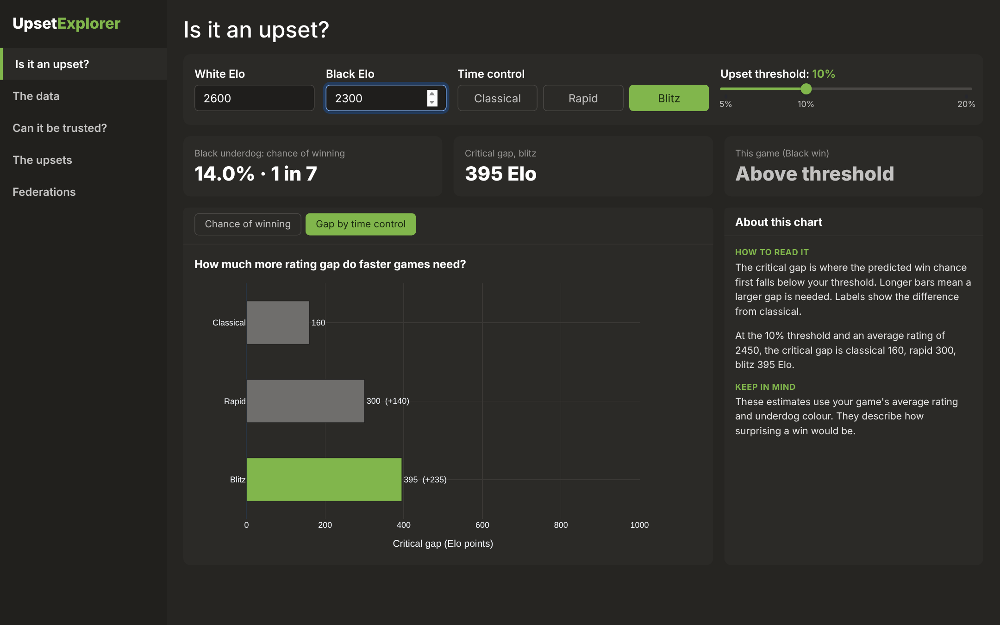

*1 is it an upset classical chance*

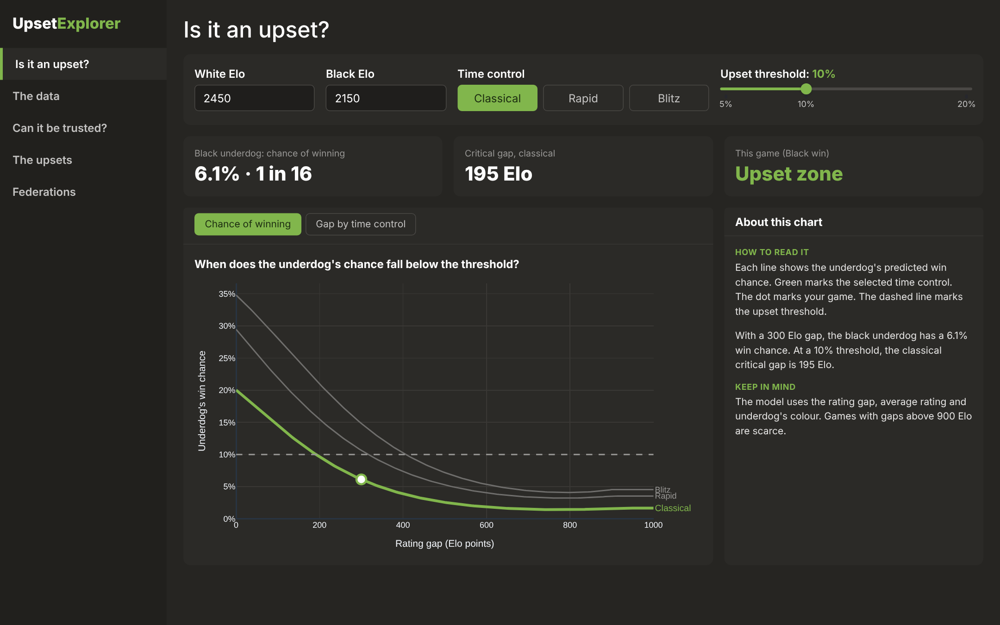

*2 the data before after cleaning*

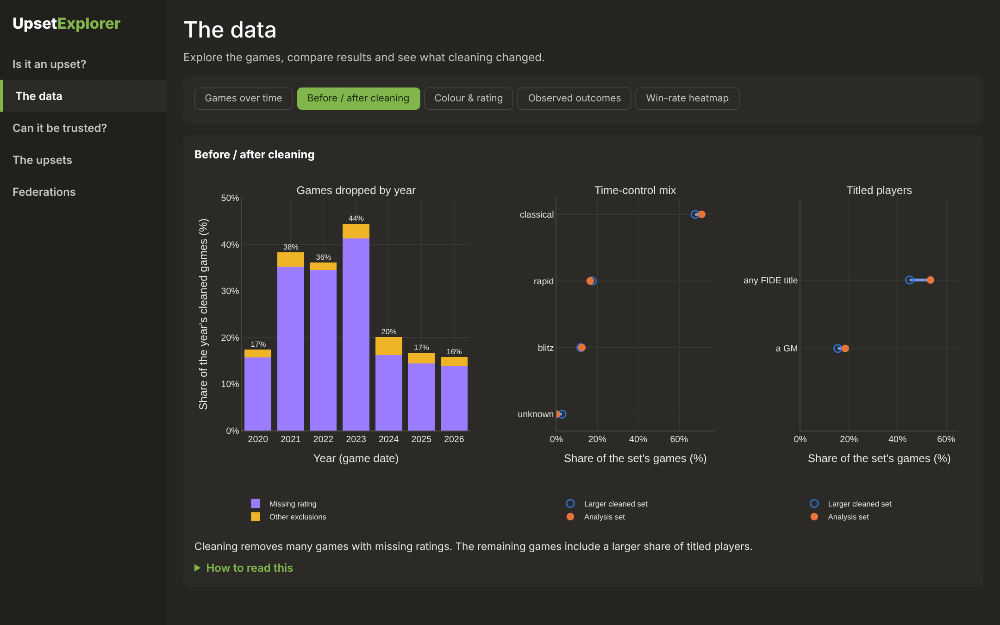

*2 the data colour and rating*

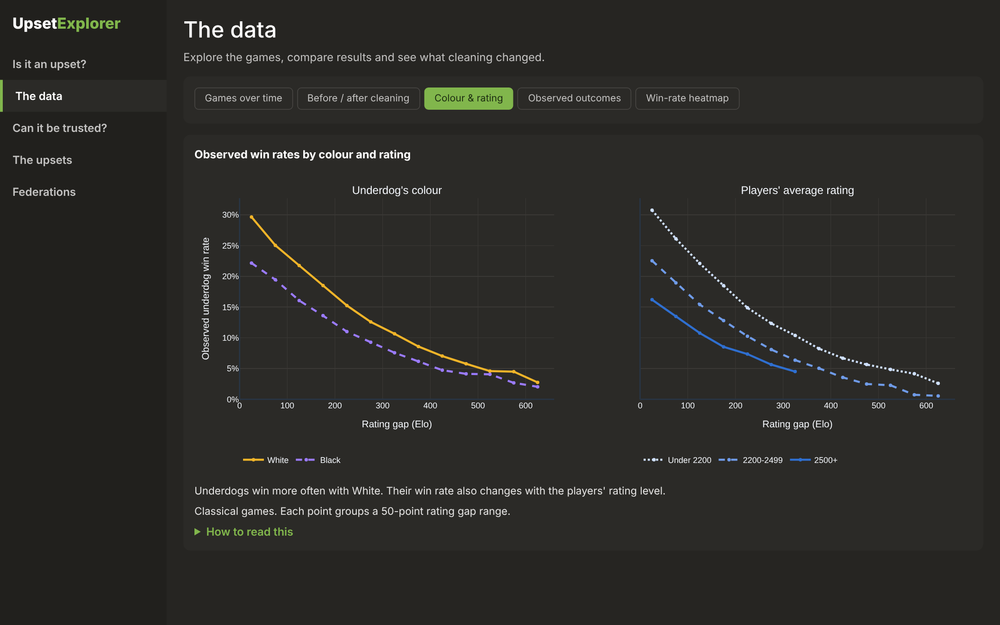

*2 the data games over time*

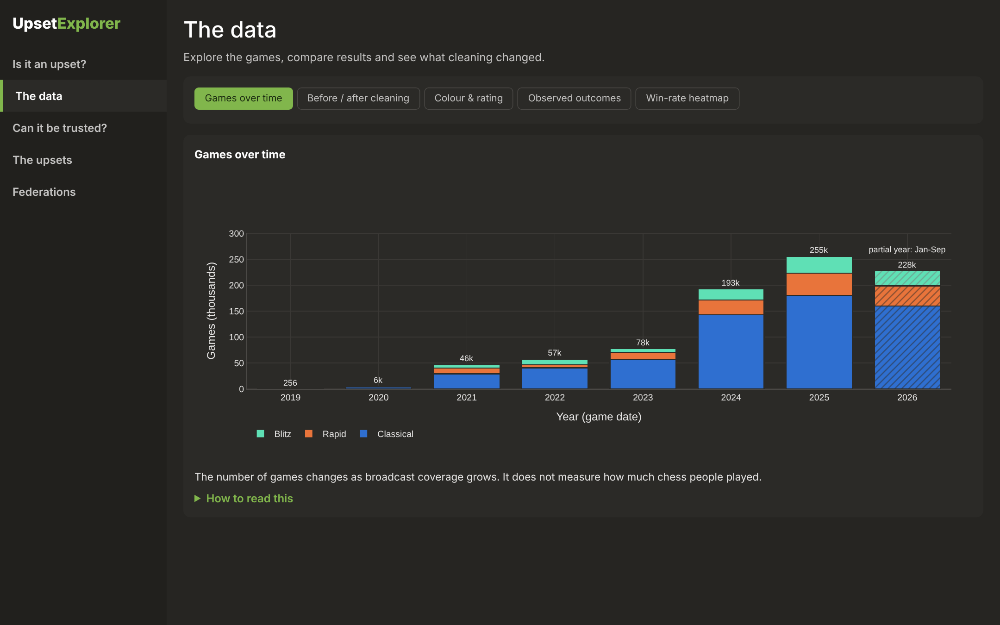

*2 the data observed outcomes*

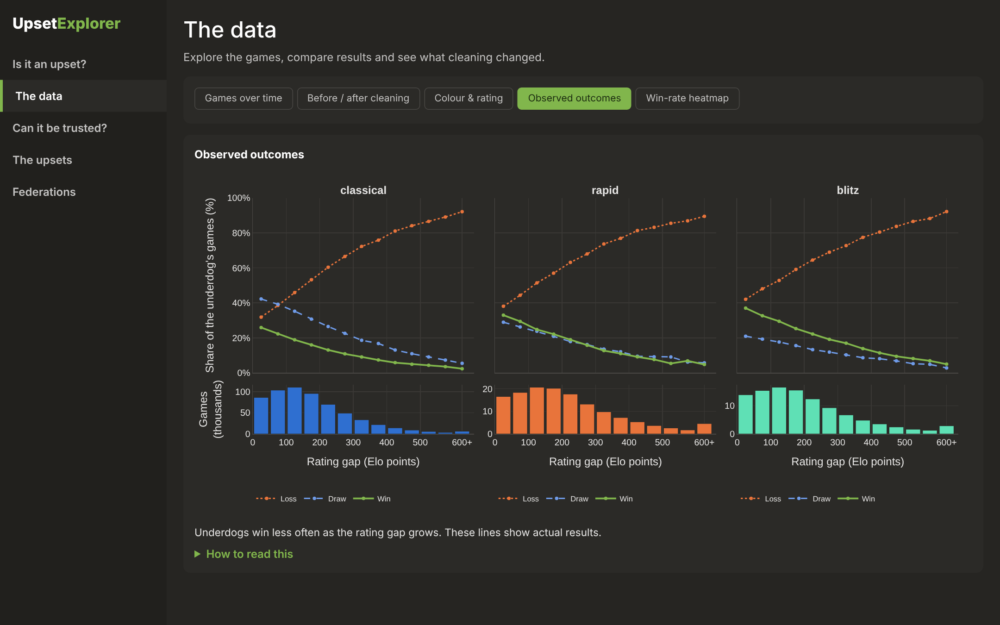

*2 the data win rate heatmap*

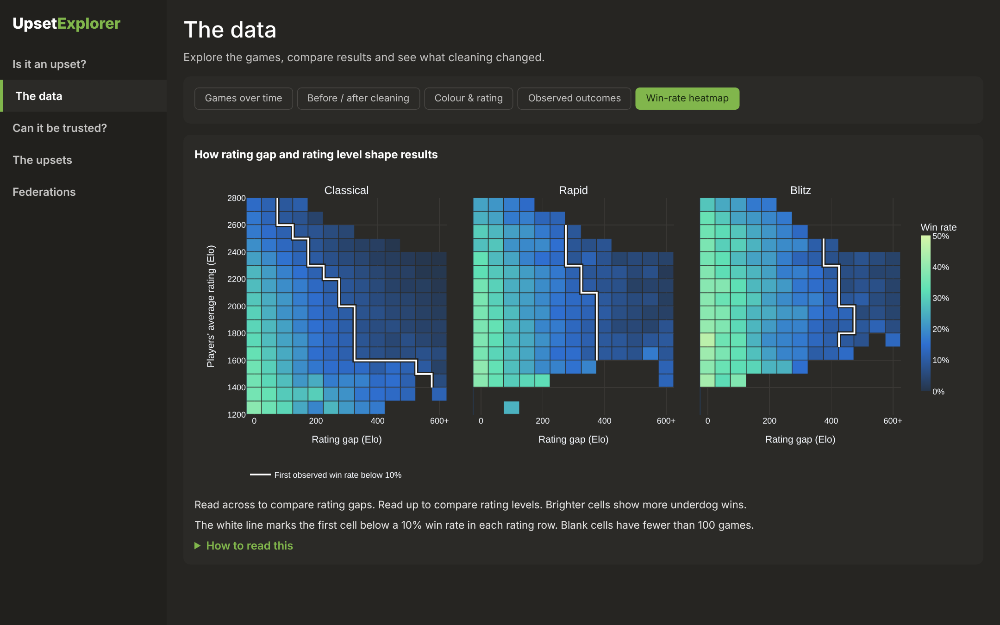

*3 can it be trusted accuracy by rating*

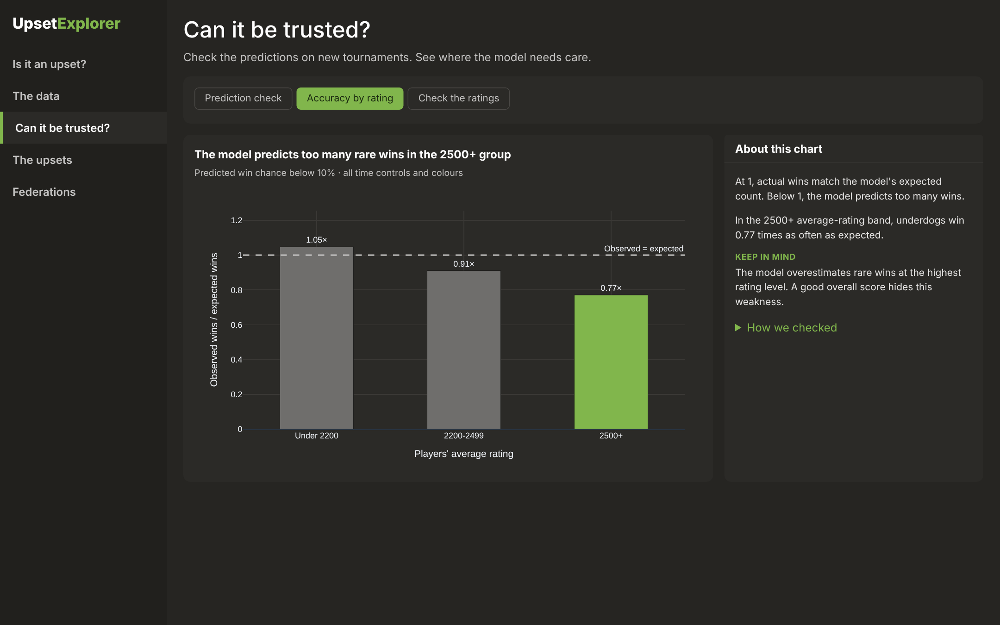

*3 can it be trusted check the ratings*

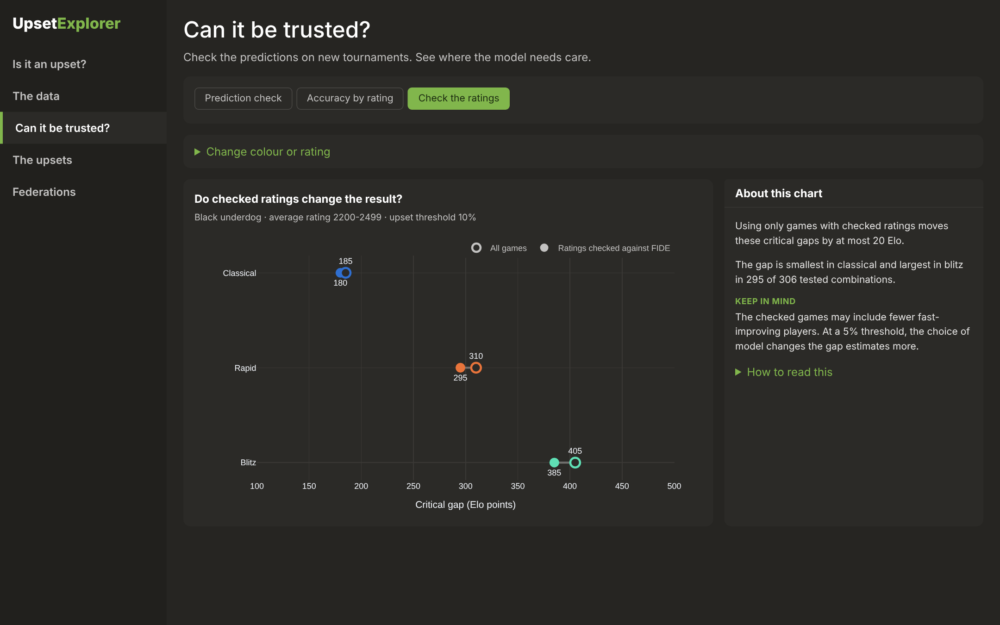

*3 can it be trusted check the ratings white 2500*

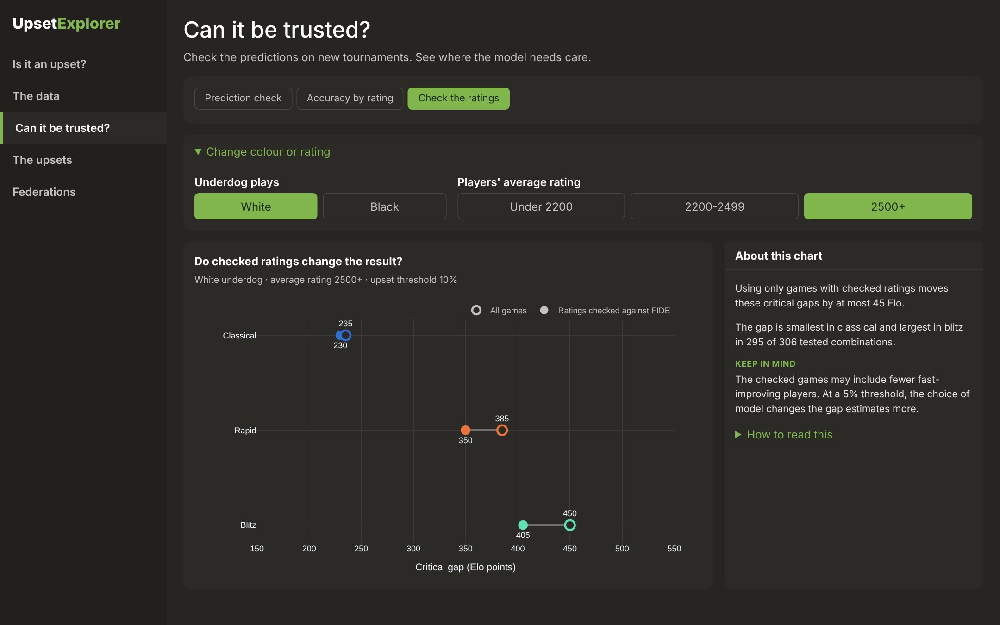

*3 can it be trusted prediction check*

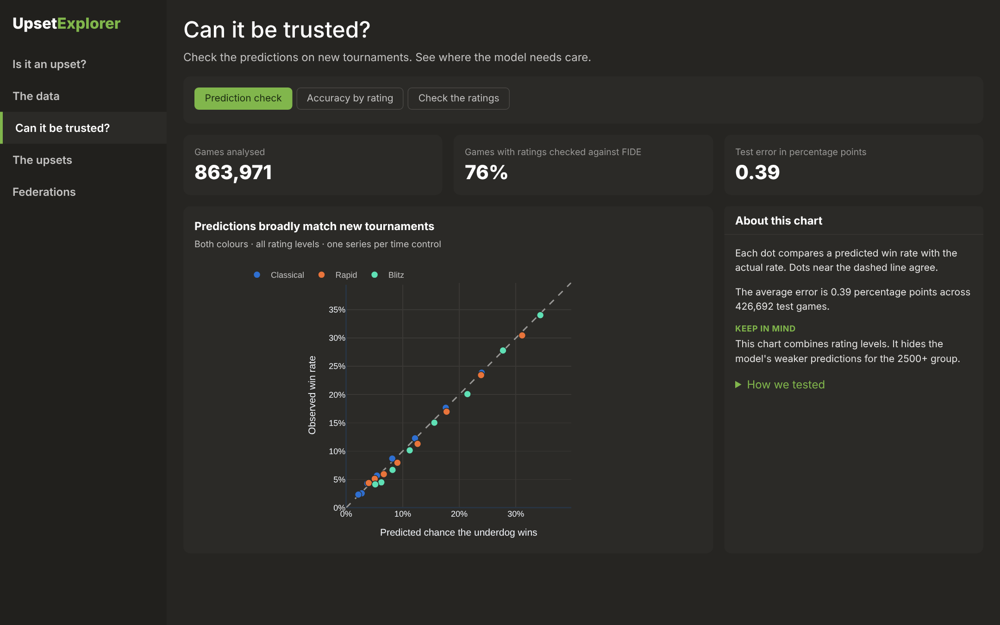

*4 the upsets game length rapid white*

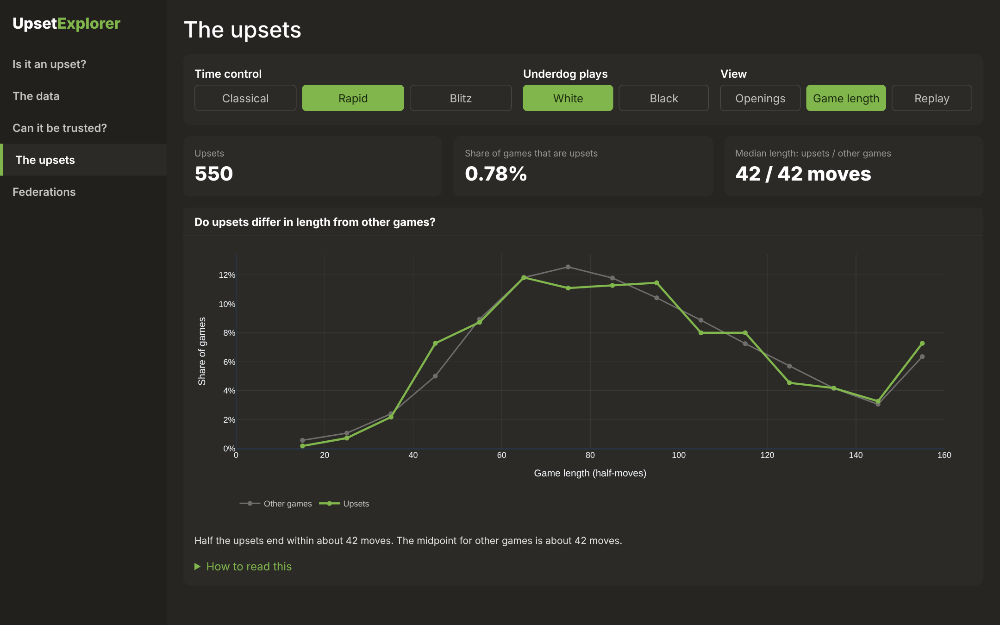

*4 the upsets openings*

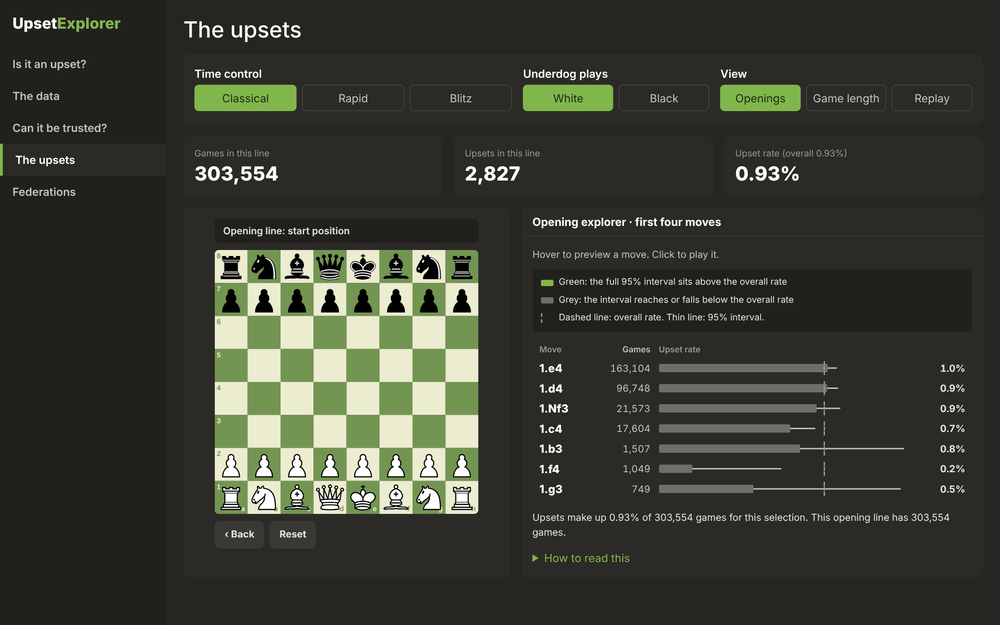

*4 the upsets openings after e4*

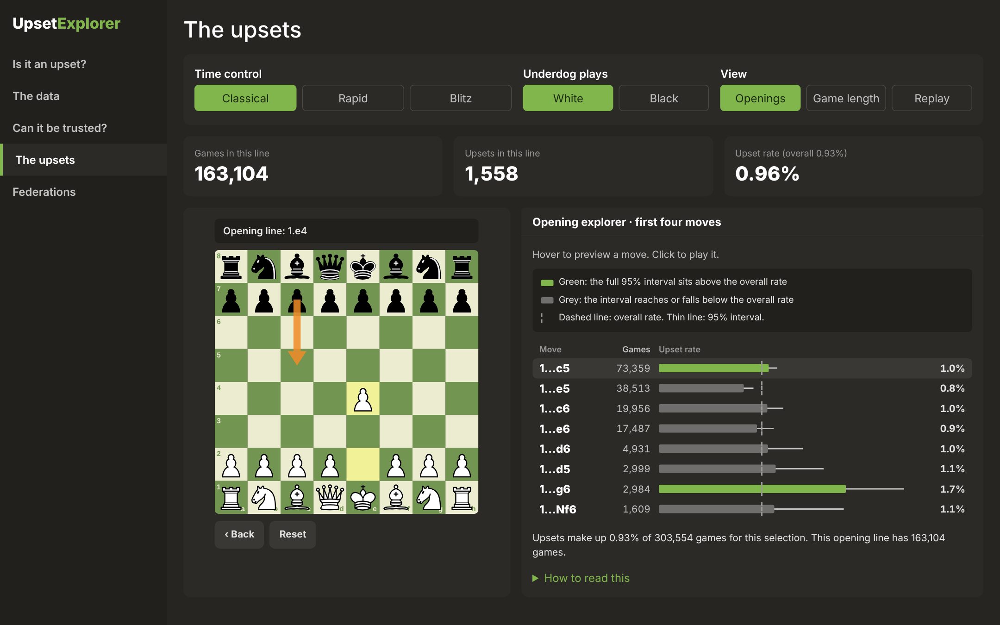

*4 the upsets replay*

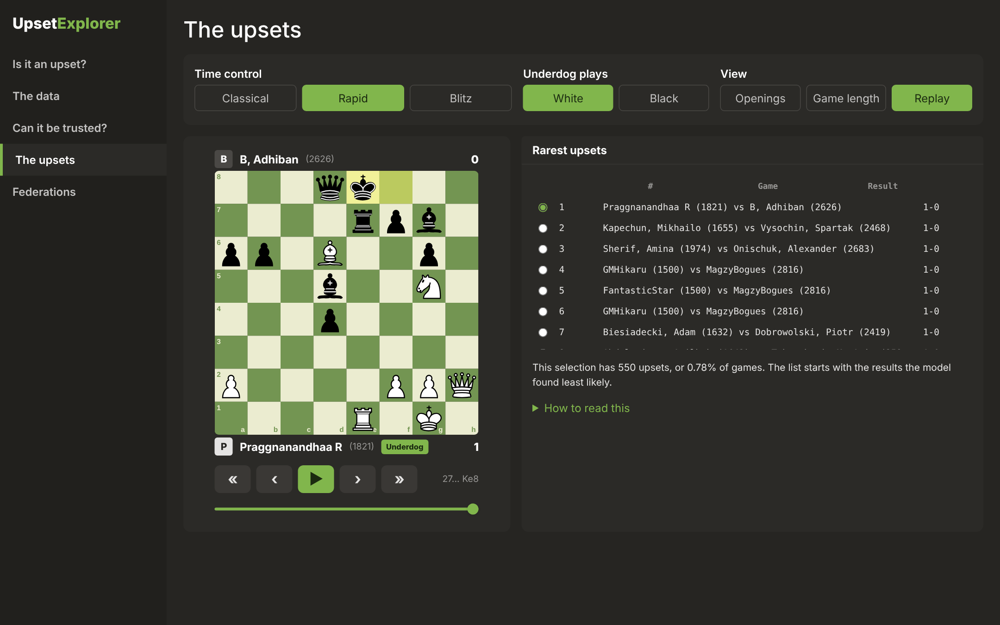

*5 federations number of upsets*

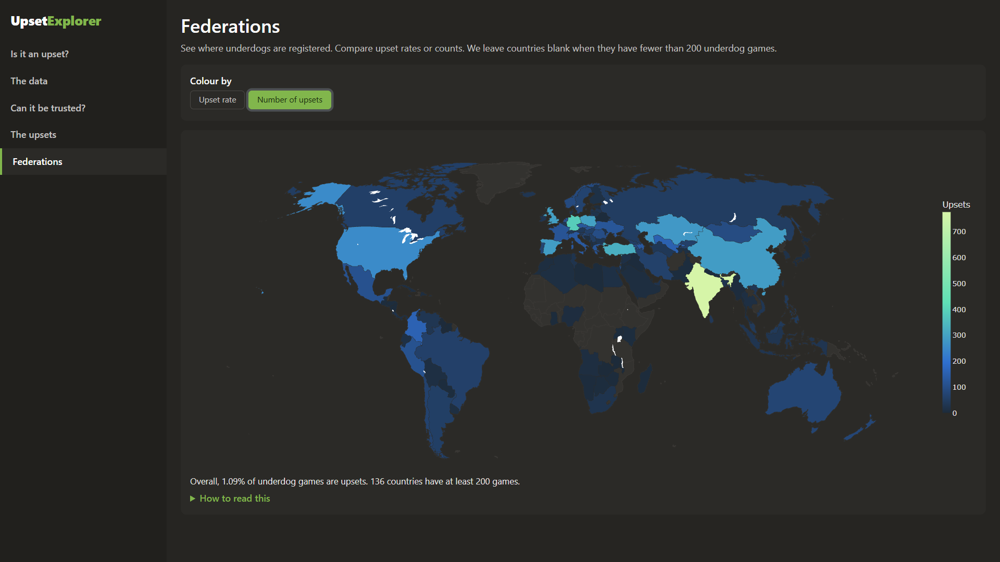

*5 federations upset rate*

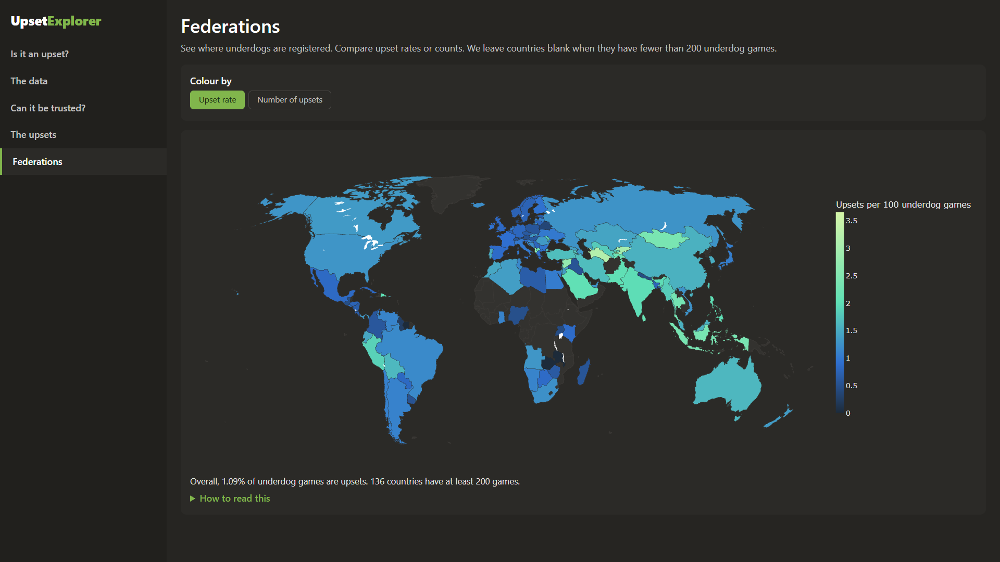

In [24]:
shots = sorted(p for p in glob.glob(os.path.join(BASE, "dashboard", "screenshots", "*"))
               if p.lower().endswith((".png", ".jpg", ".jpeg")))
for p in shots:
    md(f"*{os.path.splitext(os.path.basename(p))[0].replace('_', ' ')}*")
    display(Image(filename=p, width=900))

## 4. Conclusion

In [25]:
heat = T["heat"]
h = heat[(heat.underdog_color == "all") & (heat.tc_class == "classical") & heat.elo_lo.between(1200, 2799)].copy()
h = h[(h.n >= viz.MIN_N) & (h.wins / h.n < 0.10)]
step = h.groupby("elo_lo").gap_bin.min()
step_low, step_high = step[(step.index >= 1600) & (step.index < 2000)].median(), step[(step.index >= 2200) & (step.index < 2600)].median()
pairs = int(ordc.pairs_excluding_0.sum())
md(f"""How large must the gap be? With an upset defined as a result the fitted model gave less than a 10 % chance (alpha = 0.10), an underdog's
win in the 2200-2499 band counts as an upset from a rating gap of

| underdog | classical | rapid | blitz |
|---|---|---|---|
| White | {crit('white', 'classical', ci=True)} | {crit('white', 'rapid', ci=True)} | {crit('white', 'blitz', ci=True)} |
| Black | {crit('black', 'classical', ci=True)} | {crit('black', 'rapid', ci=True)} | {crit('black', 'blitz', ci=True)} |

(Elo points, 95 % interval in brackets). A Black underdog's win becomes an upset at a gap about
{np.mean([float(crit('white', t)) - float(crit('black', t)) for t in TCS]):.0f} points smaller than a White underdog's: the white pieces are worth roughly that many rating points to the underdog.

**Does it depend on the time control?** Yes, clearly. For a White underdog at 2200-2499, classical minus rapid is {diff('white', 'classical - rapid')}
points and classical minus blitz {diff('white', 'classical - blitz')} (median of 1,000 parameter draws, 95 % interval); for a Black underdog classical minus
blitz is {diff('black', 'classical - blitz')}. The ordering classical < rapid < blitz holds in {int(ordc.ordering_holds.sum())} of {len(ordc)} cells
(3 bands × 2 colours × alpha 0.20 / 0.10 / 0.05), {pairs} of the {3 * len(ordc)} pairwise differences have an interval that excludes 0, and it survives every
robustness run (Table 7). Faster games are more random, so an underdog needs a larger gap before its win is surprising.

**Does it depend on the players' strength?** Yes: the stronger the players, the smaller the gap that makes a result an upset. A White classical
underdog's critical gap falls from {crit('white', 'classical', band='<2200')} points (band < 2200) to {crit('white', 'classical')} (2200-2499) and
{crit('white', 'classical', band='2500+')} (2500+). The raw data show the same without any model: in classical the underdog's observed win rate first
drops below 10 % at a gap of about {step_low:.0f} points for average ratings 1600-1999, but already at {step_high:.0f} for 2200-2599 (Figure 5).

**In one sentence:** at the 10 % level, a win by the lower-rated player is an upset from about {crit('white', 'classical')} rating points in classical,
{crit('white', 'rapid')} in rapid and {crit('white', 'blitz')} in blitz (White underdog, 2200-2499), and {fmt(up.loc['all', 'obs_total'])} games in the data
({fmt(up.loc['classical', 'obs_total'])} classical, {fmt(up.loc['rapid', 'obs_total'])} rapid, {fmt(up.loc['blitz', 'obs_total'])} blitz) are upsets by this rule.""")

How large must the gap be? With an upset defined as a result the fitted model gave less than a 10 % chance (alpha = 0.10), an underdog's
win in the 2200-2499 band counts as an upset from a rating gap of

| underdog | classical | rapid | blitz |
|---|---|---|---|
| White | 280 (270-285) | 405 (385-425) | 465 (440-495) |
| Black | 185 (180-185) | 310 (300-325) | 405 (380-430) |

(Elo points, 95 % interval in brackets). A Black underdog's win becomes an upset at a gap about
83 points smaller than a White underdog's: the white pieces are worth roughly that many rating points to the underdog.

**Does it depend on the time control?** Yes, clearly. For a White underdog at 2200-2499, classical minus rapid is -125 (-150 to -105)
points and classical minus blitz -190 (-220 to -160) (median of 1,000 parameter draws, 95 % interval); for a Black underdog classical minus
blitz is -220 (-245 to -200). The ordering classical < rapid < blitz holds in 18 of 18 cells
(3 bands × 2 colours × alpha 0.20 / 0.10 / 0.05), 51 of the 54 pairwise differences have an interval that excludes 0, and it survives every
robustness run (Table 7). Faster games are more random, so an underdog needs a larger gap before its win is surprising.

**Does it depend on the players' strength?** Yes: the stronger the players, the smaller the gap that makes a result an upset. A White classical
underdog's critical gap falls from 320 points (band < 2200) to 280 (2200-2499) and
235 (2500+). The raw data show the same without any model: in classical the underdog's observed win rate first
drops below 10 % at a gap of about 350 points for average ratings 1600-1999, but already at 200 for 2200-2599 (Figure 5).

**In one sentence:** at the 10 % level, a win by the lower-rated player is an upset from about 280 rating points in classical,
405 in rapid and 465 in blitz (White underdog, 2200-2499), and 11,114 games in the data
(9,007 classical, 1,483 rapid, 624 blitz) are upsets by this rule.

## 5. Limitations

In [26]:
sc = T["set_compare"]
titled = sc[(sc.dimension == "titled") & (sc.category == "at least one FIDE title")].set_index("set").share
cav = viz.table_alpha005_caveat(T)[0]
c05 = cav[np.isclose(cav.alpha, 0.05)]
rare = T["rarest_upsets"]
md(f"""* Strong players are fitted worst. Among the games the model gives P(win) < 0.10, underdogs rated 2500+ win only
  {mis.loc[('main', 0.10, '2500+'), 'ratio']:.2f} times the expected number (rating × gap interaction model: {mis.loc[('interaction', 0.10, '2500+'), 'ratio']:.2f}),
  so the critical gaps for the 2500+ band are probably too large. The cause (elite events, quick draws, the mix of 2500 and 2700+ players) is untested.
* **alpha = 0.05 is fragile.** At alpha = 0.05 the interaction model gives critical gaps {abs(c05.change.mean()):.0f} points smaller on average
  (only {int(c05.inside_main_interval.sum())} of {len(c05)} inside the main model's interval), so the main model's alpha = 0.05 values should be
  quoted only with this caveat; the alpha = 0.10 results barely move.
* **Missing ratings.** {n_miss_elo / n_miss_base:.1%} of the cleaned games were deleted for a missing rating, and
  {myr[2021]:.0%}, {myr[2022]:.0%} and {myr[2023]:.0%} of the games of 2021, 2022 and 2023, so these years are thinly represented. Missingness is event-level (MAR); whether it also depends on the rating itself (MNAR) cannot be tested.
* **Over-representation of titled players.** The deletion changes the population: the share of games with a FIDE-titled player rises from
  {titled['clean']:.0%} in the cleaned set to {titled['analysis']:.0%} in the analysis set (Figure 6). The results describe rated tournament chess.
* **Ratings lag strength.** A published FIDE rating is up to a month old and lags fast-improving juniors, which inflates some gaps. With only the
  verified-rating games the headline critical gaps are up to {(rob['main'] - rob['verified ratings']).max():.0f} points smaller (Table 7).
* **Rating errors among the rarest upsets.** The most extreme upsets are the ones most likely to rest on a wrong or outdated rating; only
  {int(rare.elo_mismatch_any.sum())} of the {len(rare)} rarest carry a PGN-FIDE mismatch flag, but a correct-but-outdated rating cannot be detected.
  They are listed with their Lichess links in `reports/model_outputs/upset_audit_top.csv` for checking by hand.
* **Broadcast data are not all chess.** The games are events relayed on Lichess, mostly strong or notable tournaments, with growing coverage
  (Figure 1); club chess is not represented, and the time control of many games is estimated from the clocks.
* **Association, not causation.** The model describes how often underdogs won at a given gap; it does not explain why (preparation,
  form, conditions), and the intervals assume that tournaments are independent of each other.""")

* Strong players are fitted worst. Among the games the model gives P(win) < 0.10, underdogs rated 2500+ win only
  0.77 times the expected number (rating × gap interaction model: 0.78),
  so the critical gaps for the 2500+ band are probably too large. The cause (elite events, quick draws, the mix of 2500 and 2700+ players) is untested.
* **alpha = 0.05 is fragile.** At alpha = 0.05 the interaction model gives critical gaps 54 points smaller on average
  (only 4 of 18 inside the main model's interval), so the main model's alpha = 0.05 values should be
  quoted only with this caveat; the alpha = 0.10 results barely move.
* **Missing ratings.** 21.1% of the cleaned games were deleted for a missing rating, and
  35%, 35% and 41% of the games of 2021, 2022 and 2023, so these years are thinly represented. Missingness is event-level (MAR); whether it also depends on the rating itself (MNAR) cannot be tested.
* **Over-representation of titled players.** The deletion changes the population: the share of games with a FIDE-titled player rises from
  45% in the cleaned set to 54% in the analysis set (Figure 6). The results describe rated tournament chess.
* **Ratings lag strength.** A published FIDE rating is up to a month old and lags fast-improving juniors, which inflates some gaps. With only the
  verified-rating games the headline critical gaps are up to 45 points smaller (Table 7).
* **Rating errors among the rarest upsets.** The most extreme upsets are the ones most likely to rest on a wrong or outdated rating; only
  4 of the 200 rarest carry a PGN-FIDE mismatch flag, but a correct-but-outdated rating cannot be detected.
  They are listed with their Lichess links in `reports/model_outputs/upset_audit_top.csv` for checking by hand.
* **Broadcast data are not all chess.** The games are events relayed on Lichess, mostly strong or notable tournaments, with growing coverage
  (Figure 1); club chess is not represented, and the time control of many games is estimated from the clocks.
* **Association, not causation.** The model describes how often underdogs won at a given gap; it does not explain why (preparation,
  form, conditions), and the intervals assume that tournaments are independent of each other.

## 6. Attributions

**Data.**

| Source | Licence / terms | Use |
|---|---|---|
| Lichess broadcast database, https://database.lichess.org/#broadcasts, accessed 2026-10-24 | CC BY-SA 4.0 (broadcast games). Attribution: *Game data © Lichess.org contributors, CC BY-SA 4.0.* Data derived from the games are shared under the same licence | primary data |
| FIDE rating lists, https://ratings.fide.com/download_lists.phtml, accessed 2026-10-24 | © FIDE International Chess Federation, all rights reserved; no terms of use or robots.txt published | ratings filled and checked; non-commercial coursework only, not redistributed |

Libraries (versions of the environment that ran this notebook; the dashboard's libraries are listed in `dashboard/requirements.txt`):

In [27]:
LIBS = [("pandas", "tables (all notebooks)"), ("numpy", "numerics"), ("pyarrow", "Parquet storage"),
        ("zstandard", "reading the .pgn.zst files (01)"), ("requests", "downloads (01)"), ("scipy", "chi-square tests (02)"),
        ("scikit-learn", "logistic regression (03), Isolation Forest (02)"), ("plotly", "figures (04, dashboard)"),
        ("ipykernel", "running the notebooks")]
def version(p):
    try:
        return metadata.version(p)
    except metadata.PackageNotFoundError:
        return "not installed"
rows = [("Python", platform.python_version(), "language")] + [(p, version(p), use) for p, use in LIBS]
md(table(pd.DataFrame(rows, columns=["library", "version", "used for"])))

| library | version | used for |
|---|---|---|
| Python | 3.13.5 | language |
| pandas | 3.1.0 | tables (all notebooks) |
| numpy | 2.5.4 | numerics |
| pyarrow | 26.0.0 | Parquet storage |
| zstandard | 0.25.0 | reading the .pgn.zst files (01) |
| requests | 2.34.2 | downloads (01) |
| scipy | 1.18.1 | chi-square tests (02) |
| scikit-learn | 1.9.1 | logistic regression (03), Isolation Forest (02) |
| plotly | 7.1.0 | figures (04, dashboard) |
| ipykernel | 7.4.0 | running the notebooks |

**AI tools.** AI assistance: Claude (Anthropic) was used for code review and dashboard aesthetics. All code and text were checked by the team.

## 7. Contributions

| Member | Contribution | AI tools used |
|---|---|---|
| Pradish Gandhi S | Data collection, cleaning and processing | Claude (code review) |
| Mahir Ali T | Model and analysis | Claude (code review) |
| Siddharth Maira | Visualization and dashboard | Claude (code review, dashboard aesthetics) |